# 📘 3.5 2D Interpolation

### Estimating values across surfaces, maps and fields

So far in Week 3, we have mostly worked with one independent variable.

For example:

$$
v = f(t)
$$

or:

$$
C_L = f(\alpha)
$$

Many engineering problems depend on **two** independent variables.

For example:

$$
z = f(x, y)
$$

This appears in problems such as:

* pressure over a wing surface;
* temperature over a plate;
* stress over a component;
* efficiency maps for engines or pumps;
* aerodynamic coefficient tables depending on Mach number and angle of attack;
* simulation data sampled over a 2D domain.

In this notebook, we will study practical 2D interpolation using SciPy.

### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* explain what 2D interpolation is;
* distinguish between regular-grid and scattered-data interpolation;
* use `RegularGridInterpolator` for data on a rectangular or rectilinear grid;
* use `griddata` for scattered 2D data;
* identify interpolation points that are outside the data domain;
* explain why interpolation outside the convex hull of scattered data is risky;
* compare nearest, linear and cubic-style 2D interpolation methods;
* interpret interpolation error using a synthetic test case.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common engineering problems, and evaluate program performance, error, stability and accuracy.

### 📚 Sources used in this notebook

The main technical ideas in this notebook are based on:

* SciPy User Guide — Interpolation  
  https://docs.scipy.org/doc/scipy/tutorial/interpolate.html

* SciPy API Reference — RegularGridInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.RegularGridInterpolator.html

* SciPy API Reference — griddata  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.griddata.html

* SciPy API Reference — LinearNDInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.LinearNDInterpolator.html

* SciPy API Reference — CloughTocher2DInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CloughTocher2DInterpolator.html

* SciPy API Reference — NearestNDInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.NearestNDInterpolator.html

* SciPy API Reference — RBFInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.RBFInterpolator.html

* SciPy User Guide — interp2d transition guide  
  https://docs.scipy.org/doc/scipy/tutorial/interpolate/interp_transition_guide.html

## 📂 3.5.0 How to use this notebook

This is a **pre-work content notebook**. Run every code cell from top to bottom; no cell
requires editing or typed input.

The separate Week 3 workbook contains the activities to begin in Monday's workshop, continue in Wednesday's practical, and finish during revision at home.


## 📂 3.5.1 What is 2D interpolation?

In 1D interpolation, we estimate values of a function such as:

$$
y = f(x)
$$

In 2D interpolation, we estimate values of a function such as:

$$
z = f(x, y)
$$

Here:

* $x$ and $y$ are independent variables;
* $z$ is the dependent variable;
* the known data points may lie on a grid or may be scattered irregularly.

For example, in an aerodynamic pressure map:

$$
C_p = f(x/c, y/s)
$$

where:

* $x/c$ is nondimensional chord location;
* $y/s$ is nondimensional span location;
* $C_p$ is a pressure coefficient.

### Engineering interpretation

2D interpolation is useful when you know values at some locations but need estimates at other locations.

This is common when working with:

* experimental sensor layouts;
* simulation output;
* design maps;
* calibration surfaces;
* lookup tables.

## 📂 3.5.2 The most important question: grid data or scattered data?

Before choosing a method, ask:

> Are the data points arranged on a regular/rectilinear grid, or are they scattered?

### Case 1 — Regular or rectilinear grid

The data is arranged at all combinations of selected $x$ and $y$ values.

For example:

$$
x = [0.0, 0.2, 0.4, 0.6, 1.0]
$$

$$
y = [0.0, 0.5, 1.0]
$$

and values are known at every pair $(x_i, y_j)$.

A good SciPy tool for this case is:

* `RegularGridInterpolator`

### Case 2 — Scattered data

The data points are irregularly located.

For example, pressure sensors might be placed at arbitrary positions on a wing model.

A good SciPy tool for this case is:

* `griddata` for quick one-off interpolation;
* `LinearNDInterpolator` for reusable piecewise-linear interpolation;
* `CloughTocher2DInterpolator` for smoother 2D scattered interpolation;
* `NearestNDInterpolator` when nearest-neighbour behaviour is acceptable.

### ⚠️ Point of note

Using a scattered-data method on regular-grid data can be slower than necessary.

Using a regular-grid method on scattered data is usually not possible without reshaping or regridding the data.

## 📂 3.5.3 Do not use `interp2d` for new code

You may find older online examples using:

`scipy.interpolate.interp2d`

For new SciPy code, avoid this function.

The SciPy transition guide recommends newer alternatives:

| Data layout | Recommended modern tool |
|---|---|
| Regular or rectilinear grid | `RegularGridInterpolator` |
| Scattered 2D data | `LinearNDInterpolator` or `CloughTocher2DInterpolator` |
| One-off scattered interpolation onto a grid | `griddata` |

This notebook uses the modern tools.

In [ ]:
from IPython.display import display
# Core imports for this notebook

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import (
    RegularGridInterpolator,
    griddata,
    LinearNDInterpolator,
    CloughTocher2DInterpolator,
    NearestNDInterpolator,
    RBFInterpolator
)

from scipy.spatial import Delaunay

pd.set_option("display.precision", 5)

## 📂 3.5.4 Synthetic engineering field: pressure over a wing surface

We will use a synthetic pressure coefficient field.

The independent variables are:

$$
x/c
$$

and:

$$
y/s
$$

where:

* $x/c$ is nondimensional chord location;
* $y/s$ is nondimensional span location.

The dependent variable is a synthetic pressure coefficient trend:

$$
C_p = f(x/c, y/s)
$$

### ⚠️ Data note

This is synthetic teaching data, not measured wind tunnel data.

It is designed to behave like a smooth 2D engineering field so that we can compare interpolation methods against a known true function.

In [ ]:
def synthetic_pressure_coefficient(x_over_c, y_over_half_span):
    """
    Synthetic pressure coefficient field for teaching 2D interpolation.

    This is not measured airfoil or wing data.

    Parameters
    ----------
    x_over_c : array-like
        Nondimensional chord location.

    y_over_half_span : array-like
        Nondimensional span location.

    Returns
    -------
    array-like
        Synthetic pressure coefficient value.
    """
    x_over_c = np.asarray(x_over_c, dtype=float)
    y_over_half_span = np.asarray(y_over_half_span, dtype=float)

    leading_edge_suction = -1.15 * np.exp(-((x_over_c - 0.12) / 0.16) ** 2)
    chord_recovery = 0.35 * x_over_c
    span_effect = 0.18 * y_over_half_span ** 2
    mild_wave = 0.08 * np.sin(2 * np.pi * x_over_c) * (1 - 0.4 * y_over_half_span)

    return leading_edge_suction + chord_recovery + span_effect + mild_wave

## 📂 3.5.5 Regular-grid interpolation

First, suppose we have pressure values on a rectilinear grid.

The grid spacing does not need to be uniform.

For example, we might sample more points near the leading edge because the pressure changes rapidly there.

This is a common engineering strategy: put more measurement or simulation points where the gradients are larger.

In [ ]:
# Rectilinear grid.
# The x/c spacing is deliberately nonuniform, with more points near the leading edge.

x_grid = np.array([0.00, 0.05, 0.10, 0.20, 0.35, 0.60, 1.00], dtype=float)
y_grid = np.array([0.00, 0.25, 0.50, 0.75, 1.00], dtype=float)

# Create a full grid of node coordinates.
# indexing="ij" gives arrays shaped as (len(x_grid), len(y_grid)).
X_nodes, Y_nodes = np.meshgrid(x_grid, y_grid, indexing="ij")

# Values at every grid node.
cp_grid = synthetic_pressure_coefficient(X_nodes, Y_nodes)

pressure_table = pd.DataFrame(
    cp_grid,
    index=[f"x/c={x:.2f}" for x in x_grid],
    columns=[f"y/s={y:.2f}" for y in y_grid]
)

pressure_table

,y/s=0.00,y/s=0.25,y/s=0.50,y/s=0.75,y/s=1.00
x/c=0.00,-0.65525,-0.64400,-0.61025,-0.55400,-0.47525
x/c=0.05,-0.90745,-0.89867,-0.86739,-0.81361,-0.73733
x/c=0.10,-1.05015,-1.04360,-1.01455,-0.96300,-0.88896
x/c=0.20,-0.74954,-0.74589,-0.71975,-0.67111,-0.59997
x/c=0.35,0.04159,0.04636,0.07364,0.12342,0.19570
x/c=0.60,0.16284,0.17879,0.21724,0.27819,0.36164
x/c=1.00,0.35000,0.36125,0.39500,0.45125,0.53000


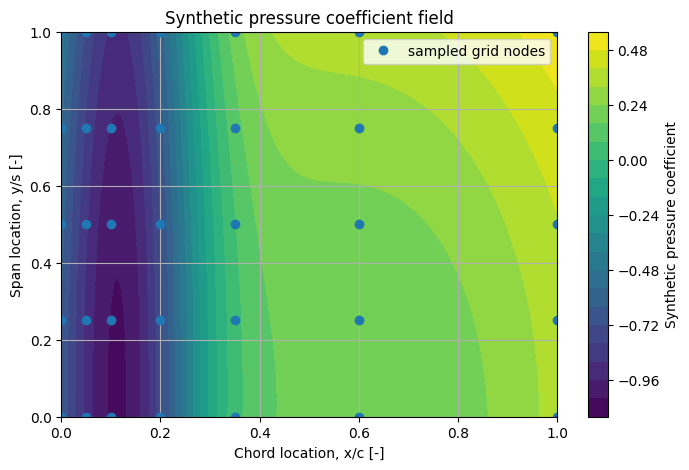

In [ ]:
# Dense grid used only for plotting and error checking.

x_dense = np.linspace(x_grid.min(), x_grid.max(), 160)
y_dense = np.linspace(y_grid.min(), y_grid.max(), 120)

X_dense, Y_dense = np.meshgrid(x_dense, y_dense, indexing="ij")

cp_true_dense = synthetic_pressure_coefficient(X_dense, Y_dense)

fig, ax = plt.subplots(figsize=(8, 5))

contour = ax.contourf(X_dense, Y_dense, cp_true_dense, levels=20)
fig.colorbar(contour, ax=ax, label="Synthetic pressure coefficient")

ax.plot(X_nodes.ravel(), Y_nodes.ravel(), "o", label="sampled grid nodes")

ax.set_xlabel("Chord location, x/c [-]")
ax.set_ylabel("Span location, y/s [-]")
ax.set_title("Synthetic pressure coefficient field")
ax.grid(True)
ax.legend()

plt.show()

> ### 🧩 Code Explanation
>
> `np.meshgrid` creates 2D coordinate arrays from the 1D grid arrays.
>
> The option `indexing="ij"` is used so that the first axis corresponds to `x_grid` and the second axis corresponds to `y_grid`.
>
> This matters because `RegularGridInterpolator` expects the values array to match the shape of the coordinate arrays:
>
> $$
> \text{values.shape} = (\text{len}(x), \text{len}(y))
> $$
>
> Axis ordering mistakes are one of the most common bugs in 2D interpolation.

## 📂 3.5.6 Building a `RegularGridInterpolator`

We will compare three methods:

| Method | Behaviour |
|---|---|
| `nearest` | Uses the nearest grid node value |
| `linear` | Linear interpolation between grid nodes |
| `cubic` | Smoother spline-style interpolation, requiring enough points in each dimension |

A higher-order method is not automatically better.

It can be smoother, but it may also overshoot or behave poorly if the grid is coarse or the field changes rapidly.

In [ ]:
regular_methods = ["nearest", "linear", "cubic"]

regular_interpolators = {}

for method in regular_methods:
    regular_interpolators[method] = RegularGridInterpolator(
        (x_grid, y_grid),
        cp_grid,
        method=method,
        bounds_error=False,
        fill_value=np.nan
    )

In [ ]:
# Query points.
# The final point is intentionally outside the x/c domain.

query_points = np.array([
    [0.12, 0.10],
    [0.30, 0.60],
    [0.80, 0.25],
    [1.10, 0.50]
], dtype=float)

query_table = pd.DataFrame({
    "x_over_c": query_points[:, 0],
    "y_over_half_span": query_points[:, 1],
    "true_for_teaching_only": synthetic_pressure_coefficient(query_points[:, 0], query_points[:, 1]),
    "nearest": regular_interpolators["nearest"](query_points),
    "linear": regular_interpolators["linear"](query_points),
    "cubic": regular_interpolators["cubic"](query_points)
})

query_table

,x_over_c,y_over_half_span,true_for_teaching_only,nearest,linear,cubic
0,0.12,0.10,-1.05363,-1.05015,-0.98764,-1.04599
1,0.30,0.60,-0.09675,0.07364,-0.17106,-0.14326
2,0.80,0.25,0.22277,0.36125,0.27002,-0.09330
3,1.10,0.50,0.46762,NaN,NaN,NaN


### 🧠 What should you notice?

The interpolation methods give different estimates at the same query points.

The point with $x/c = 1.10$ lies outside the sampled domain because the original grid only covers:

$$
0 \le x/c \le 1
$$

Because we set `bounds_error=False` and `fill_value=np.nan`, the interpolator returns `NaN` for that out-of-range query.

This is useful because it prevents extrapolated values from silently entering an engineering calculation.

In [ ]:
# Evaluate all interpolators on the dense plotting grid.

points_dense = np.column_stack([X_dense.ravel(), Y_dense.ravel()])

regular_error_rows = []

for method, interpolator in regular_interpolators.items():
    cp_predicted_dense = interpolator(points_dense).reshape(X_dense.shape)

    valid = ~np.isnan(cp_predicted_dense)

    rmse_value = np.sqrt(
        np.mean((cp_predicted_dense[valid] - cp_true_dense[valid]) ** 2)
    )

    max_abs_error = np.max(
        np.abs(cp_predicted_dense[valid] - cp_true_dense[valid])
    )

    regular_error_rows.append({
        "method": method,
        "RMSE_against_true_field": rmse_value,
        "max_abs_error": max_abs_error
    })

regular_error_table = pd.DataFrame(regular_error_rows)

regular_error_table

,method,RMSE_against_true_field,max_abs_error
0,nearest,0.11018,0.47979
1,linear,0.04477,0.09727
2,cubic,0.15272,0.33964


### 🧠 Interpretation

In this synthetic example, we know the true field, so we can calculate interpolation error directly.

In real engineering problems, the true field is usually unknown.

You would instead need to use:

* validation measurements;
* mesh refinement studies;
* repeated tests;
* physical reasoning;
* sensitivity analysis;
* conservation checks;
* uncertainty estimates.

### ⚠️ Point of note

The lowest-error method in this synthetic example is not guaranteed to be the best method for every engineering problem.

Interpolation method choice depends on the data layout, smoothness, noise level, domain shape, and purpose of the calculation.

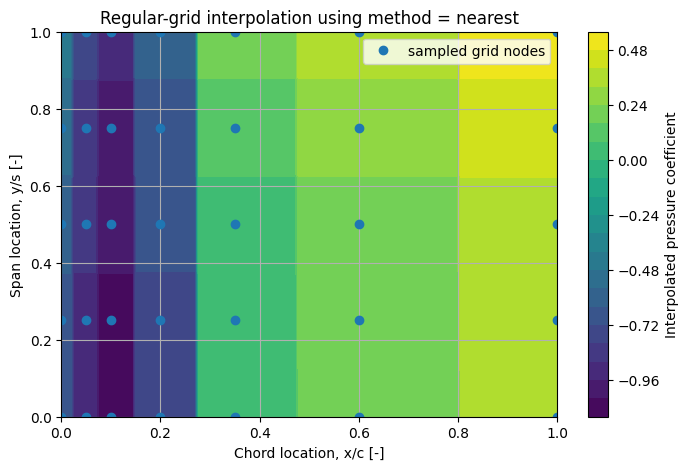

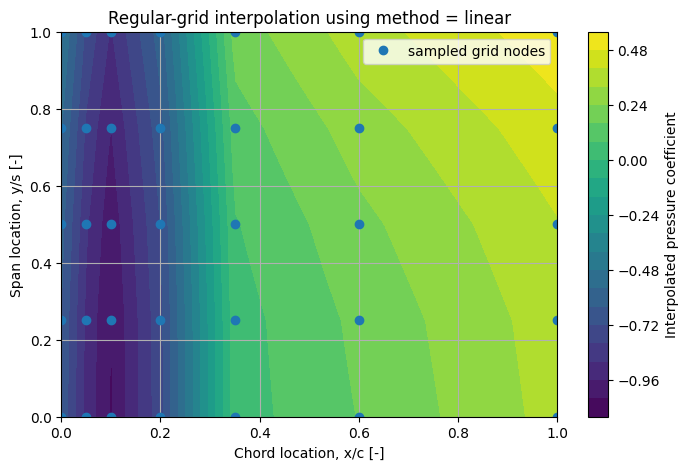

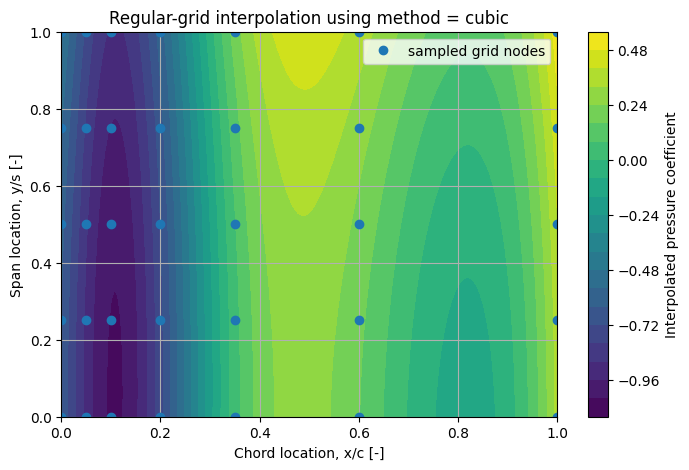

In [ ]:
# Plot the interpolated fields.

for method, interpolator in regular_interpolators.items():
    cp_interp_dense = interpolator(points_dense).reshape(X_dense.shape)

    fig, ax = plt.subplots(figsize=(8, 5))

    contour = ax.contourf(X_dense, Y_dense, cp_interp_dense, levels=20)
    fig.colorbar(contour, ax=ax, label="Interpolated pressure coefficient")

    ax.plot(X_nodes.ravel(), Y_nodes.ravel(), "o", label="sampled grid nodes")

    ax.set_xlabel("Chord location, x/c [-]")
    ax.set_ylabel("Span location, y/s [-]")
    ax.set_title(f"Regular-grid interpolation using method = {method}")
    ax.grid(True)
    ax.legend()

    plt.show()

## 📂 3.5.7 Checking whether a regular-grid query is inside the domain

For regular-grid interpolation, a simple domain check is:

$$
x_\text{min} \le x^* \le x_\text{max}
$$

and:

$$
y_\text{min} \le y^* \le y_\text{max}
$$

If both are true, the query is inside the rectangular grid domain.

If either condition fails, the query is outside the rectangular grid domain.

In [ ]:
def classify_regular_grid_points(query_points, x_axis, y_axis):
    """
    Classify 2D query points as interpolation or extrapolation
    for a rectangular or rectilinear grid.

    Parameters
    ----------
    query_points : ndarray with shape (n_points, 2)
        Query coordinates arranged as [x, y].

    x_axis : array-like
        Known x-axis grid values.

    y_axis : array-like
        Known y-axis grid values.

    Returns
    -------
    ndarray
        "interpolation" if the query is inside the rectangular domain,
        otherwise "extrapolation".
    """
    query_points = np.asarray(query_points, dtype=float)

    inside_x = (
        (query_points[:, 0] >= np.min(x_axis)) &
        (query_points[:, 0] <= np.max(x_axis))
    )

    inside_y = (
        (query_points[:, 1] >= np.min(y_axis)) &
        (query_points[:, 1] <= np.max(y_axis))
    )

    return np.where(inside_x & inside_y, "interpolation", "extrapolation")


bounds_table = pd.DataFrame({
    "x_over_c": query_points[:, 0],
    "y_over_half_span": query_points[:, 1],
    "region": classify_regular_grid_points(query_points, x_grid, y_grid),
    "linear_prediction": regular_interpolators["linear"](query_points)
})

bounds_table

,x_over_c,y_over_half_span,region,linear_prediction
0,0.12,0.10,interpolation,-0.98764
1,0.30,0.60,interpolation,-0.17106
2,0.80,0.25,interpolation,0.27002
3,1.10,0.50,extrapolation,NaN


## 📂 3.5.8 Worked extension — regular-grid interpolation

Change the query points and interpolation method below.

Suggested methods:

* `nearest`
* `linear`
* `cubic`

### Questions

1. Which points are interpolation?
2. Which points are extrapolation?
3. Which method gives the smoothest-looking result?
4. Which method gives the smallest error against the synthetic true function?
5. Does the smoothest method always give the smallest error?

In [ ]:
# Demonstration setting: Change these values and rerun the cell.

student_method = "linear"

student_query_points = np.array([
    [0.15, 0.20],
    [0.50, 0.50],
    [0.95, 0.85]
], dtype=float)

student_interpolator = regular_interpolators[student_method]

student_predictions = student_interpolator(student_query_points)

student_results = pd.DataFrame({
    "x_over_c": student_query_points[:, 0],
    "y_over_half_span": student_query_points[:, 1],
    "region": classify_regular_grid_points(student_query_points, x_grid, y_grid),
    "predicted_CP": student_predictions,
    "true_for_teaching_only": synthetic_pressure_coefficient(
        student_query_points[:, 0],
        student_query_points[:, 1]
    )
})

student_results["absolute_error"] = np.abs(
    student_results["predicted_CP"] - student_results["true_for_teaching_only"]
)

student_results

,x_over_c,y_over_half_span,region,predicted_CP,true_for_teaching_only,absolute_error
0,0.15,0.20,interpolation,-0.89577,-0.99103,0.09526
1,0.50,0.50,interpolation,0.15980,0.21592,0.05612
2,0.95,0.85,interpolation,0.46135,0.44623,0.01512


## 📂 3.5.9 Scattered-data interpolation

Now suppose the data points are not arranged on a grid.

This occurs when measurements are taken at irregular sensor locations.

Examples include:

* pressure taps placed around structural constraints;
* thermocouples attached at accessible locations;
* strain gauges placed near expected high-stress regions;
* particle image velocimetry data with masked regions;
* simulation output projected onto an irregular surface mesh.

For scattered data, we cannot use `RegularGridInterpolator` directly.

Instead, we can use tools such as:

* `griddata`;
* `NearestNDInterpolator`;
* `LinearNDInterpolator`;
* `CloughTocher2DInterpolator`;
* `RBFInterpolator`.

In [ ]:
# Generate scattered sensor locations.

rng = np.random.default_rng(21)

n_sensors = 75

sensor_x = rng.uniform(0.03, 0.97, n_sensors)
sensor_y = rng.uniform(0.03, 0.97, n_sensors)

sensor_points = np.column_stack([sensor_x, sensor_y])
sensor_cp = synthetic_pressure_coefficient(sensor_x, sensor_y)

sensor_data = pd.DataFrame({
    "x_over_c": sensor_x,
    "y_over_half_span": sensor_y,
    "cp_value": sensor_cp
})

sensor_data.head()

,x_over_c,y_over_half_span,cp_value
0,0.76425,0.86948,0.35160
1,0.59950,0.78590,0.28875
2,0.69721,0.14374,0.17645
3,0.11375,0.76998,-0.96543
4,0.62287,0.04420,0.16348


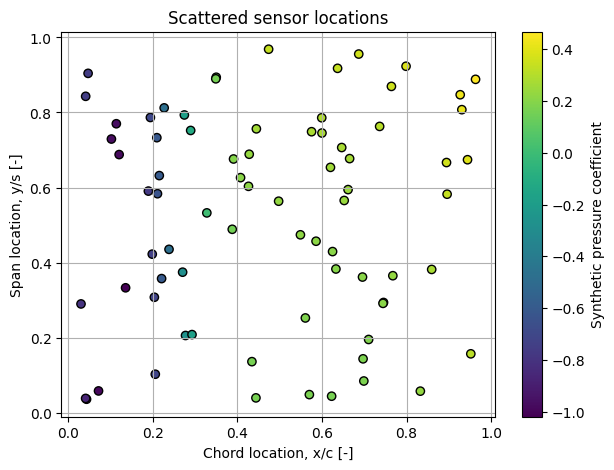

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

scatter = ax.scatter(sensor_x, sensor_y, c=sensor_cp, edgecolor="k")
fig.colorbar(scatter, ax=ax, label="Synthetic pressure coefficient")

ax.set_xlabel("Chord location, x/c [-]")
ax.set_ylabel("Span location, y/s [-]")
ax.set_title("Scattered sensor locations")
ax.grid(True)

plt.show()

## 📂 3.5.10 Using `griddata`

`griddata` is useful when we have scattered points and want to interpolate onto a set of requested points or onto a plotting grid.

We will compare:

| Method | Behaviour |
|---|---|
| `nearest` | Uses value at nearest scattered data point |
| `linear` | Piecewise linear interpolation over a triangulation |
| `cubic` | Smooth 2D cubic-style interpolation using a Clough-Tocher approach |

### ⚠️ Point of note

For scattered data, `linear` and `cubic` methods generally return `NaN` outside the convex hull of the data points.

Nearest-neighbour interpolation can still return a value outside the convex hull, but that does not mean the value is reliable.

In [ ]:
scattered_methods = ["nearest", "linear", "cubic"]

scattered_grid_results = {}

for method in scattered_methods:
    scattered_grid_results[method] = griddata(
        sensor_points,
        sensor_cp,
        (X_dense, Y_dense),
        method=method
    )

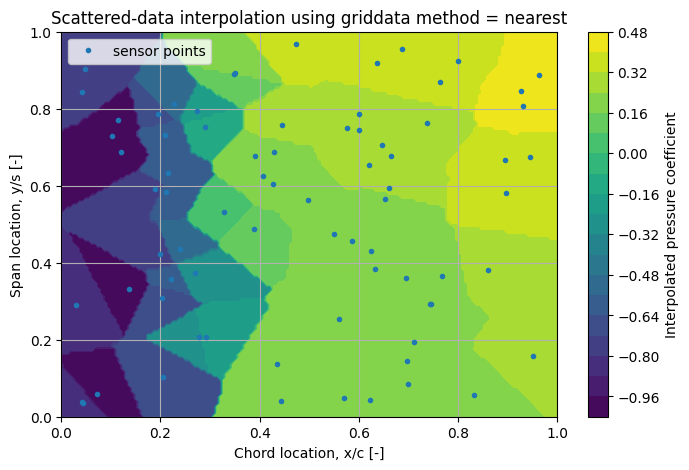

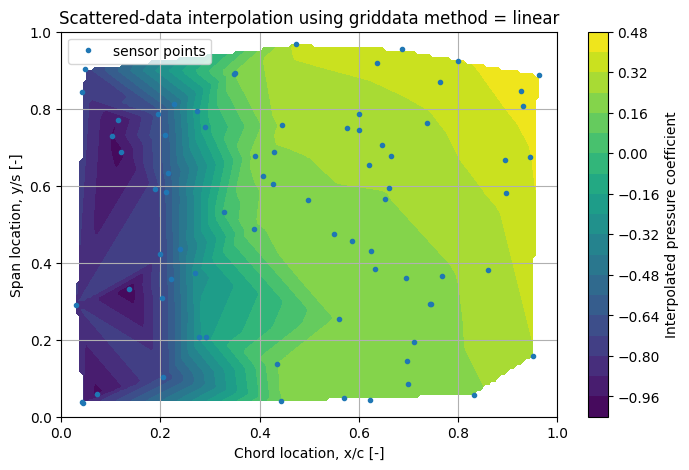

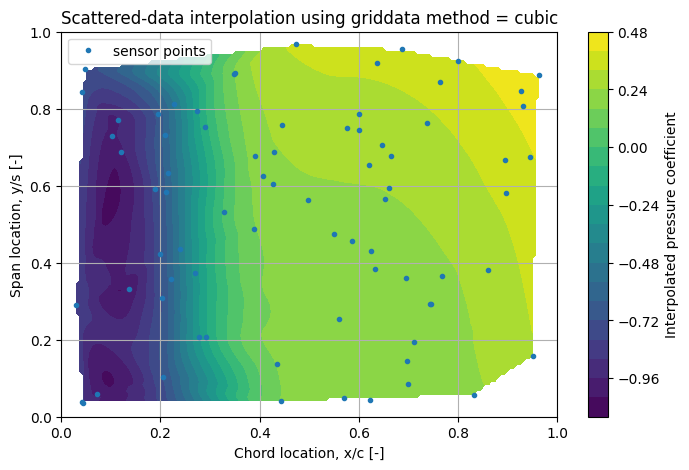

In [ ]:
for method, cp_scattered_interp in scattered_grid_results.items():
    fig, ax = plt.subplots(figsize=(8, 5))

    contour = ax.contourf(X_dense, Y_dense, cp_scattered_interp, levels=20)
    fig.colorbar(contour, ax=ax, label="Interpolated pressure coefficient")

    ax.plot(sensor_x, sensor_y, "o", markersize=3, label="sensor points")

    ax.set_xlabel("Chord location, x/c [-]")
    ax.set_ylabel("Span location, y/s [-]")
    ax.set_title(f"Scattered-data interpolation using griddata method = {method}")
    ax.grid(True)
    ax.legend()

    plt.show()

In [ ]:
scattered_error_rows = []

for method, cp_scattered_interp in scattered_grid_results.items():
    valid = ~np.isnan(cp_scattered_interp)

    scattered_error_rows.append({
        "method": method,
        "valid_fraction_of_plot_grid": np.mean(valid),
        "RMSE_against_true_field_where_valid": np.sqrt(
            np.mean((cp_scattered_interp[valid] - cp_true_dense[valid]) ** 2)
        )
    })

scattered_error_table = pd.DataFrame(scattered_error_rows)

scattered_error_table

,method,valid_fraction_of_plot_grid,RMSE_against_true_field_where_valid
0,nearest,1.00000,0.12009
1,linear,0.80479,0.08120
2,cubic,0.80479,0.03965


### 🧠 What should you notice?

The valid fraction may be less than 1 for `linear` and `cubic` scattered interpolation.

That is because these methods generally interpolate inside the convex hull of the sensor points.

They do not automatically fill regions outside the sensor coverage.

This is a good thing: it warns us that the data does not support those regions well.

### ⚠️ Engineering warning

A filled contour plot can look authoritative, but it may hide unsupported regions.

Always check where the measurements were taken.

## 📂 3.5.11 Convex hull and unsupported regions

For scattered data, the **convex hull** is the smallest convex region that contains all the data points.

In 2D, you can imagine stretching a rubber band around the outermost data points.

Interpolation inside this region is usually more defensible than prediction outside it.

### Important distinction

For regular-grid data, the domain check is usually rectangular.

For scattered data, the domain check depends on the convex hull of the points.

A point can be inside the rectangular bounding box but still outside the convex hull.

In [ ]:
# Build a Delaunay triangulation for convex hull checks.

triangulation = Delaunay(sensor_points)


def classify_scattered_points(query_points, triangulation):
    """
    Classify 2D query points as inside or outside the convex hull
    of scattered data points.

    Parameters
    ----------
    query_points : ndarray with shape (n_points, 2)
        Query coordinates arranged as [x, y].

    triangulation : scipy.spatial.Delaunay
        Delaunay triangulation built from the scattered data points.

    Returns
    -------
    ndarray
        Region labels.
    """
    query_points = np.asarray(query_points, dtype=float)

    inside = triangulation.find_simplex(query_points) >= 0

    return np.where(inside, "inside convex hull", "outside convex hull")

In [ ]:
scattered_query_points = np.array([
    [0.30, 0.40],
    [0.95, 0.95],
    [0.01, 0.50]
], dtype=float)

scattered_query_table = pd.DataFrame({
    "x_over_c": scattered_query_points[:, 0],
    "y_over_half_span": scattered_query_points[:, 1],
    "region": classify_scattered_points(scattered_query_points, triangulation),
    "nearest": griddata(sensor_points, sensor_cp, scattered_query_points, method="nearest"),
    "linear": griddata(sensor_points, sensor_cp, scattered_query_points, method="linear"),
    "cubic": griddata(sensor_points, sensor_cp, scattered_query_points, method="cubic")
})

scattered_query_table

,x_over_c,y_over_half_span,region,nearest,linear,cubic
0,0.30,0.40,inside convex hull,-0.28723,-0.18219,-0.12837
1,0.95,0.95,outside convex hull,0.46731,NaN,NaN
2,0.01,0.50,outside convex hull,-0.76603,NaN,NaN


### 🧠 What should you notice?

The `nearest` method returns values even outside the convex hull.

The `linear` and `cubic` methods return `NaN` for points outside the convex hull.

This does not mean nearest-neighbour extrapolation is accurate.

It only means the algorithm can select the nearest known point.

### ⚠️ Point of note

If a result is outside the convex hull, report it as unsupported or extrapolated unless you have a separate physical justification.

## 📂 3.5.12 Reusable scattered-data interpolators

`griddata` is convenient for one-off interpolation.

If you need to evaluate many query points repeatedly, it can be more convenient to build an interpolator object.

SciPy provides several callable interpolators.

We will compare:

* `NearestNDInterpolator`
* `LinearNDInterpolator`
* `CloughTocher2DInterpolator`

In [ ]:
nearest_nd = NearestNDInterpolator(sensor_points, sensor_cp)

linear_nd = LinearNDInterpolator(
    sensor_points,
    sensor_cp,
    fill_value=np.nan
)

clough_tocher = CloughTocher2DInterpolator(
    sensor_points,
    sensor_cp,
    fill_value=np.nan
)

callable_query_table = pd.DataFrame({
    "x_over_c": scattered_query_points[:, 0],
    "y_over_half_span": scattered_query_points[:, 1],
    "region": classify_scattered_points(scattered_query_points, triangulation),
    "NearestNDInterpolator": nearest_nd(scattered_query_points),
    "LinearNDInterpolator": linear_nd(scattered_query_points),
    "CloughTocher2DInterpolator": clough_tocher(scattered_query_points)
})

callable_query_table

,x_over_c,y_over_half_span,region,NearestNDInterpolator,LinearNDInterpolator,CloughTocher2DInterpolator
0,0.30,0.40,inside convex hull,-0.28723,-0.18219,-0.12837
1,0.95,0.95,outside convex hull,0.46731,NaN,NaN
2,0.01,0.50,outside convex hull,-0.76603,NaN,NaN


### 🧠 Interpretation

The callable interpolators produce results similar to the corresponding `griddata` methods.

The main difference is workflow:

* use `griddata` for quick one-off interpolation;
* use interpolator objects when you want to build once and evaluate many times.

This is similar to fitting a model once and then using it repeatedly.

## 📂 3.5.13 Radial basis function interpolation

Another option for scattered data is radial basis function interpolation.

SciPy provides:

`RBFInterpolator`

RBF methods can create smooth interpolating surfaces from scattered data.

They can be useful, but they also require care because:

* the result can depend on kernel choice;
* the result can depend on smoothing settings;
* large datasets can become computationally expensive;
* extrapolation outside the data cloud can be misleading.

We will use a simple RBF interpolator as a demonstration.

In [ ]:
rbf_interpolator = RBFInterpolator(
    sensor_points,
    sensor_cp,
    kernel="thin_plate_spline",
    smoothing=0.0
)

rbf_grid = rbf_interpolator(points_dense).reshape(X_dense.shape)

valid_inside_hull = triangulation.find_simplex(points_dense) >= 0
valid_inside_hull = valid_inside_hull.reshape(X_dense.shape)

rbf_rmse_inside = np.sqrt(
    np.mean((rbf_grid[valid_inside_hull] - cp_true_dense[valid_inside_hull]) ** 2)
)

print(f"RBF RMSE inside convex hull: {rbf_rmse_inside:.5f}")

RBF RMSE inside convex hull: 0.04480


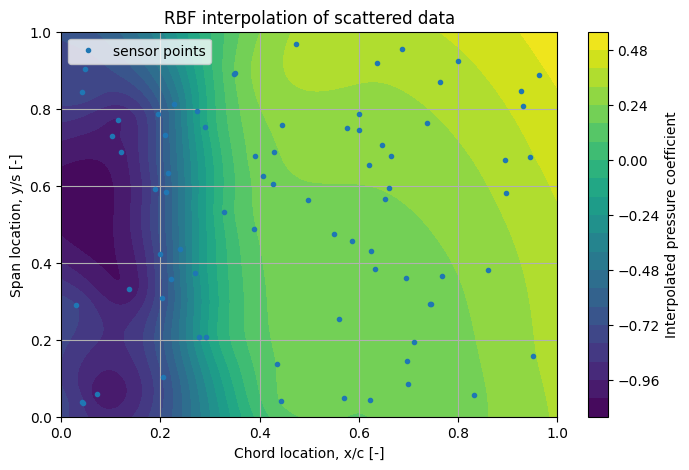

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

contour = ax.contourf(X_dense, Y_dense, rbf_grid, levels=20)
fig.colorbar(contour, ax=ax, label="Interpolated pressure coefficient")

ax.plot(sensor_x, sensor_y, "o", markersize=3, label="sensor points")

ax.set_xlabel("Chord location, x/c [-]")
ax.set_ylabel("Span location, y/s [-]")
ax.set_title("RBF interpolation of scattered data")
ax.grid(True)
ax.legend()

plt.show()

### ⚠️ Engineering warning

The RBF plot fills the whole rectangular plotting region.

That does not mean the entire plotted region is well-supported by data.

For scattered-data interpolation, always check where the data points are and whether the query point is inside the supported region.

## 📂 3.5.14 Method selection summary

| Situation | Possible method | Comment |
|---|---|---|
| Data on a regular or rectilinear grid | `RegularGridInterpolator` | Good default for grid-based lookup tables |
| Scattered data, quick interpolation onto a grid | `griddata` | Convenient for plotting and one-off calculations |
| Scattered data, nearest value acceptable | `NearestNDInterpolator` | Fast and simple, but discontinuous |
| Scattered data, reusable linear interpolation | `LinearNDInterpolator` | Piecewise linear, returns `NaN` outside convex hull |
| Scattered data, smoother 2D interpolation | `CloughTocher2DInterpolator` | Smooth but may overshoot or be sensitive |
| Smooth scattered-data surface | `RBFInterpolator` | Flexible but needs care with settings and extrapolation |

### Practical rule

Do not start by asking, "Which function do I use?"

Start by asking:

1. What is the data layout?
2. Is the data noisy?
3. Do I need a smooth surface?
4. Do I need derivatives?
5. Are my query points inside the supported domain?
6. How will I validate the interpolated values?

## 📂 3.5.15 Worked extension — scattered-data interpolation experiment

Change the number of sensors and interpolation method below.

Suggested values for `student_n_sensors`:

* 15
* 30
* 75
* 150

Suggested values for `student_method`:

* `nearest`
* `linear`
* `cubic`

### Questions

1. What happens when the number of sensors is small?
2. Which method gives the most complete coverage?
3. Which method gives the smoothest surface?
4. Which method gives the lowest RMSE where valid?
5. What happens near the edges of the data cloud?

In [ ]:
# Demonstration setting: Modify these values and rerun the cell.

student_n_sensors = 40
student_method = "linear"

rng_student = np.random.default_rng(123)

student_sensor_x = rng_student.uniform(0.03, 0.97, student_n_sensors)
student_sensor_y = rng_student.uniform(0.03, 0.97, student_n_sensors)

student_sensor_points = np.column_stack([student_sensor_x, student_sensor_y])

student_sensor_cp = synthetic_pressure_coefficient(
    student_sensor_x,
    student_sensor_y
)

student_cp_grid = griddata(
    student_sensor_points,
    student_sensor_cp,
    (X_dense, Y_dense),
    method=student_method
)

valid = ~np.isnan(student_cp_grid)

student_rmse = np.sqrt(
    np.mean((student_cp_grid[valid] - cp_true_dense[valid]) ** 2)
)

valid_fraction = np.mean(valid)

print(f"Method: {student_method}")
print(f"Number of sensors: {student_n_sensors}")
print(f"Valid fraction of plotting grid: {valid_fraction:.3f}")
print(f"RMSE where valid: {student_rmse:.5f}")

Method: linear
Number of sensors: 40
Valid fraction of plotting grid: 0.631
RMSE where valid: 0.11196


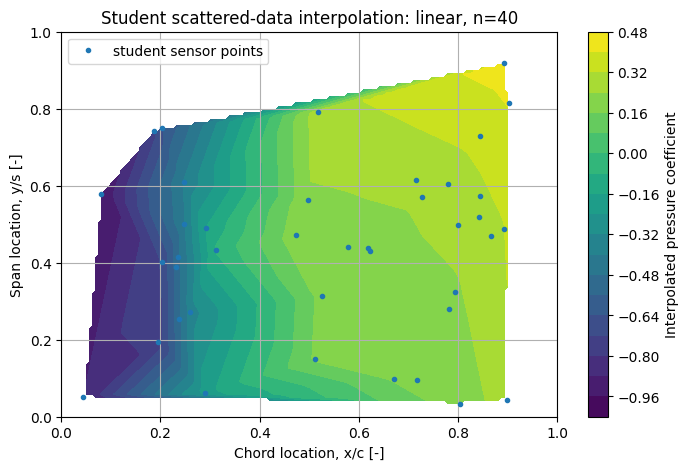

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

contour = ax.contourf(X_dense, Y_dense, student_cp_grid, levels=20)
fig.colorbar(contour, ax=ax, label="Interpolated pressure coefficient")

ax.plot(student_sensor_x, student_sensor_y, "o", markersize=3, label="student sensor points")

ax.set_xlabel("Chord location, x/c [-]")
ax.set_ylabel("Span location, y/s [-]")
ax.set_title(f"Student scattered-data interpolation: {student_method}, n={student_n_sensors}")
ax.grid(True)
ax.legend()

plt.show()

## 📂 3.5.16 Worked extension — design a sensor layout

Work individually or in pairs.

You are designing a pressure sensor layout for a wing surface.

You can place 25 sensors.

Your goal is to reconstruct the pressure field across the wing using interpolation.

### Discussion questions

1. Would you place sensors uniformly?
2. Would you place more sensors near the leading edge?
3. Would you place more sensors near the boundaries?
4. How would you check whether your interpolated surface is reliable?
5. Which interpolation method would you start with, and why?

### Extension idea

Modify the scattered sensor generation code so that sensors are concentrated near the leading edge.

Compare the interpolation error with the random uniform sensor layout.

## 📂 3.5.17 Recommended resources

### Reading

* SciPy User Guide — Interpolation  
  https://docs.scipy.org/doc/scipy/tutorial/interpolate.html

* SciPy API Reference — RegularGridInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.RegularGridInterpolator.html

* SciPy API Reference — griddata  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.griddata.html

* SciPy API Reference — LinearNDInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.LinearNDInterpolator.html

* SciPy API Reference — CloughTocher2DInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CloughTocher2DInterpolator.html

* SciPy API Reference — RBFInterpolator  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.RBFInterpolator.html

* SciPy User Guide — interp2d transition guide  
  https://docs.scipy.org/doc/scipy/tutorial/interpolate/interp_transition_guide.html

### Videos

* Search topic: 2D interpolation SciPy RegularGridInterpolator  
  https://www.youtube.com/results?search_query=2D+interpolation+SciPy+RegularGridInterpolator

* Search topic: scattered data interpolation SciPy griddata  
  https://www.youtube.com/results?search_query=scattered+data+interpolation+SciPy+griddata

## 📂 3.5.18 Engineering workflow and summary

When solving a 2D interpolation problem, first determine how the data is organised.

- Use **regular-grid interpolation** when values are known on a rectangular or rectilinear grid.

- Use **scattered-data interpolation** when observations are available at irregular coordinate locations.

- Use **nearest-neighbour interpolation** when a nearby supported value is preferable to a smooth estimate.

- Use **linear interpolation** when simple local behaviour and limited artificial curvature are important.

- Use **smoother methods** carefully, because visually smooth surfaces can introduce unsupported features.

- Treat **radial-basis-function interpolation** as a modelling choice that requires validation, particularly outside well-sampled regions.

The main lessons from this notebook are:

- regular-grid and scattered-data problems require different interpolation tools;

- RegularGridInterpolator is suitable for structured grid data;

- griddata and reusable scattered-data interpolators are suitable for irregularly located observations;

- coordinate order, array shape, units, and scaling must be checked before trusting a result;

- a query can lie inside the minimum and maximum of both coordinates while still being outside the convex hull of scattered data;

- nearest-neighbour methods may return values outside the convex hull, but this does not make those values reliable;

- interpolation error depends on the method, data spacing, sampling geometry, and behaviour of the underlying field;

- missing or unsupported regions should be identified clearly rather than hidden by a smooth-looking surface.

A defensible 2D interpolation workflow should:

1. classify the data as regular-grid or scattered;

2. plot the sampling locations and inspect their coverage;

3. verify coordinate order and units;

4. test the interpolator at known data locations;

5. identify the geometric domain that supports each query;

6. compare methods using known or withheld values where possible;

7. report unsupported regions, assumptions, and likely sources of error.

A smooth contour plot is a visual representation is **not** evidence that the interpolated field is physically correct.


### 📚 Current software documentation checked

The implementation guidance in this notebook was checked against the current stable
documentation on 25 July 2026:

* SciPy 1.17 interpolation guide: https://docs.scipy.org/doc/scipy/tutorial/interpolate.html
* SciPy interpolation API: https://docs.scipy.org/doc/scipy/reference/interpolate.html
* scikit-learn 1.9 documentation (where used): https://scikit-learn.org/stable/


## 📚 References

1. SciPy Developers, SciPy User Guide, Interpolation.  
   https://docs.scipy.org/doc/scipy/tutorial/interpolate.html

2. SciPy Developers, `scipy.interpolate.RegularGridInterpolator`.  
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.RegularGridInterpolator.html

3. SciPy Developers, `scipy.interpolate.griddata`.  
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.griddata.html

4. SciPy Developers, `scipy.interpolate.LinearNDInterpolator`.  
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.LinearNDInterpolator.html

5. SciPy Developers, `scipy.interpolate.CloughTocher2DInterpolator`.  
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CloughTocher2DInterpolator.html

6. SciPy Developers, `scipy.interpolate.NearestNDInterpolator`.  
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.NearestNDInterpolator.html

7. SciPy Developers, `scipy.interpolate.RBFInterpolator`.  
   https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.RBFInterpolator.html

8. SciPy Developers, SciPy User Guide, `interp2d` transition guide.  
   https://docs.scipy.org/doc/scipy/tutorial/interpolate/interp_transition_guide.html

## 🤖 AI Acknowledgment

Parts of this notebook were developed with the assistance of AI tools for drafting explanations, code structure, and student prompts.

All technical content, code, references, and examples have been reviewed and adapted for MMA3001 teaching purposes.

Students should treat AI-generated explanations and code as starting points only. Numerical outputs should be checked using plots, tests, documentation, and engineering judgement.